# code_007 · Vectors, matrices and tensors as data

**Book:** Chapter 2, section 2.1. **Scope:** a mathematics laboratory, with exact toy models and generated data. This is not a field-validation study or an exhaustive estimator-constructor lab. All imports, inputs and helpers are contained here.

Use the [quickstart](../README.md) and [pinned environment](../requirements-lock.txt), then restart and run all cells. The reference environment is CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1 and Matplotlib 3.11.0, macOS ARM64 CPU. No data downloads, API keys, GPU or project imports are needed. Allow a minute for execution and 30–60 minutes for predictions and exercises. Actual runtime appears at the end and in [execution evidence](../CHAPTER_02_EXECUTION.md).

Read each prediction before revealing output. Controls here are coordinate choices, numerical-method settings and stated system/data assumptions; they are not collectively model hyperparameters. These constructed mechanism checks do not need a supervised train/test split. A later fitted predictive pipeline must learn scales and representations on training data only. See the [concept-to-code guide](../CHAPTER_02_GUIDE.md) and [stable code directory](../CODE_EXAMPLES.md#code_007).


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter(); SEED=202
rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,
'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine())
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,
'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64


<a id="shape-ledger"></a>
## Shape and units ledger

Rows identify three synthetic members; columns are length in m, load in kN and deflection in mm. Each coefficient below turns its feature into an invented dimensionless score. The score is an affine calculation, not a calibrated damage probability. A dot product contracts the feature axis; elementwise multiplication alone does not sum it. NumPy vectors of shape `(p,)` have no separate row/column orientation.

**Predict:** which of `X*w`, `X@w`, and `X.T@X` has one scalar per member? Can a valid matrix product detect that the load column was accidentally expressed in N while its coefficient still expects kN?


In [2]:
X=np.array([[3.,10.,.4],[4.,20.,.8],[5.,30.,1.2]])
w=np.array([.1,.02,.5]); bias=.3
ledger=pd.DataFrame({'axis':['rows','column 0','column 1','column 2'],
'meaning':['member A/B/C','length','load','deflection'],'unit':['identity','m','kN','mm']})
display(ledger)
score=X@w+bias
assert np.allclose(score,np.sum(X*w,axis=1)+bias)
assert (X*w).shape==(3,3) and score.shape==(3,)
print('X:',X.shape,'w:',w.shape,'scores:',score)
wrong_units=X.copy();wrong_units[:,1]*=1000
print('Same shape, wrong units:',wrong_units@w+bias)
RESULTS['scores']=score.tolist()


,axis,meaning,unit
0,rows,member A/B/C,identity
1,column 0,length,m
2,column 1,load,kN
3,column 2,deflection,mm


X: (3, 3) w: (3,) scores: [1.  1.5 2. ]
Same shape, wrong units: [200.8 401.1 601.4]


<a id="broadcast"></a>
## Successful broadcasting, wrong pairing

A column mean broadcasts intentionally across observations. A column-shaped prediction minus a flat target broadcasts both axes, comparing all pairs. Shapes must be equal before a paired loss; flatten only after establishing that both refer to the same ordered observations. The assertion catches a semantic mismatch with a clear expectation instead of relying on a NumPy exception.

**Predict:** what is the off-diagonal entry in row A, column C of the accidental error matrix? Will equal predictions and targets make that all-pairs loss zero?


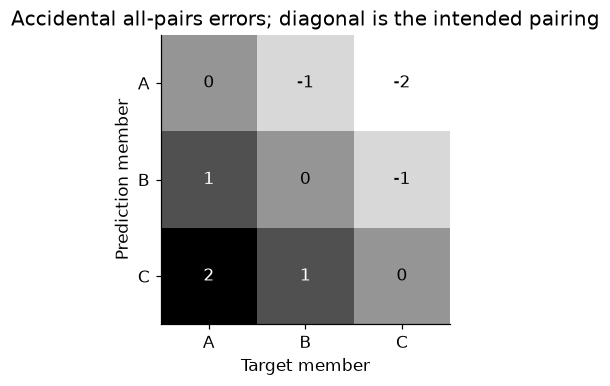

In [3]:
centered=X-X.mean(axis=0)
assert np.allclose(centered.mean(0),0)
y=np.array([1.,2.,3.]);pred=y[:,None]
paired=pred[:,0]-y;all_pairs=pred-y
assert all_pairs.shape==(3,3) and all_pairs[0,2]==-2
assert np.mean(paired**2)==0 and np.mean(all_pairs**2)>0
fig,ax=plt.subplots(figsize=(6,3.4))
im=ax.imshow(all_pairs,cmap='Greys',vmin=-2,vmax=2)
for i in range(3):
 for j in range(3):ax.text(j,i,f'{all_pairs[i,j]:.0f}',ha='center',va='center',color='white' if all_pairs[i,j]>0 else 'black')
ax.set(xticks=range(3),yticks=range(3),xticklabels=['A','B','C'],yticklabels=['A','B','C'],xlabel='Target member',ylabel='Prediction member',title='Accidental all-pairs errors; diagonal is the intended pairing')
plt.show()
RESULTS['paired_mse']=float(np.mean(paired**2));RESULTS['accidental_mse']=float(np.mean(all_pairs**2))


<a id="equilibrium"></a>
## Two springs, fixed left support

The free-node order is internal node, endpoint. `K` has units N/m, `f` is N and `u` is m. The fixed node is excluded. Internal balance is `(k1+k2)*u1-k2*u2=0`; endpoint balance is `k2*(u2-u1)=100`. We solve, multiply back and independently recover spring tensions. This verifies the specified linear static model, not a real structure.

**Predict:** why should endpoint displacement exceed internal displacement? What singular mode would reappear if the whole unconstrained chain could translate?


In [4]:
k1,k2=2000.,1000.
K=np.array([[k1+k2,-k2],[-k2,k2]])
f=np.array([0.,100.]);u=np.linalg.solve(K,f)
tensions=np.array([k1*u[0],k2*(u[1]-u[0])])
assert u.shape==f.shape==(2,) and np.allclose(u,[.05,.15])
assert np.allclose(K@u,f) and np.allclose(tensions,100.)
K_free=np.array([[k1,-k1,0],[-k1,k1+k2,-k2],[0,-k2,k2]])
assert np.allclose(K_free@np.ones(3),0) and np.linalg.matrix_rank(K_free)==2
print('u [m]:',u,'tensions [N]:',tensions,'residual [N]:',np.linalg.norm(K@u-f))
RESULTS['displacements_m']=u.tolist();RESULTS['tensions_N']=tensions.tolist()


u [m]: [0.05 0.15] tensions [N]: [100. 100.] residual [N]: 0.0


<a id="graph-batches"></a>
## Graphs of unequal sizes

A block-diagonal adjacency keeps separate structures disconnected. `graph_id` controls pooling. Padding is an alternative but zeros added for storage are not observed zero features; a mask must exclude them. Here node features are dimensionless scalar readings and adjacency aggregation is a neighbor sum, not a learned GNN or equilibrium solve. The same bookkeeping extends to `(batch,time,sensor,channel)` arrays once the meaning and missingness of every axis are specified.

**Predict:** why is a pooled mean over all five nodes different from the mean of two graph means? Which is appropriate depends on whether the unit of averaging is node or structure.


In [5]:
A1=np.array([[0.,1.],[1.,0.]]);A2=np.array([[0.,1.,0.],[1.,0.,1.],[0.,1.,0.]])
features=[np.array([[1.],[3.]]),np.array([[2.],[4.],[9.]])]
A=np.zeros((5,5));A[:2,:2]=A1;A[2:,2:]=A2
H=np.concatenate(features);graph_id=np.array([0,0,1,1,1])
assert np.allclose(A@H,np.concatenate([A1@features[0],A2@features[1]]))
assert not A[:2,2:].any() and not A[2:,:2].any()
padded=np.zeros((2,3,1));mask=np.zeros((2,3),dtype=bool)
for g,h in enumerate(features):padded[g,:len(h)]=h;mask[g,:len(h)]=True
masked_means=(padded[:,:,0]*mask).sum(1)/mask.sum(1)
separate_means=np.array([H[graph_id==g].mean() for g in range(2)])
assert np.allclose(masked_means,separate_means)
print('Graph means:',masked_means,'unmasked padded means:',padded.mean(1).ravel())
RESULTS['graph_means']=masked_means.tolist()


Graph means: [2. 5.] unmasked padded means: [1.33333333 5.        ]


<a id="exercises"></a>
## Exercises and optional hints

1. Give the affine score physical target units instead of invented score units. Write units for each coefficient and intercept.
2. Intentionally permute target rows. Explain why a shape assertion cannot detect the wrong pairing; add an ID-alignment check.
3. Add a nonzero internal force and predict the two spring tensions before solving. Check global reaction balance.
4. Replace adjacency sums by degree-normalized means. Handle an isolated node explicitly and compare separate versus batched outputs.
5. Design a ledger for three structures with irregular sensor times; say what padding and masks mean.

**Hints:** use labelled IDs for pairing; the internal force makes tensions unequal; average graph means equally only when structures have equal averaging weight. A missing boundary condition is a modelling error rather than a dtype choice.

**Troubleshooting:** `@` needs matching contracted axes; a NumPy vector transpose alone changes nothing. Before fixing a singular solve, inspect supports and rigid modes. See official [broadcasting](https://numpy.org/doc/stable/user/basics.broadcasting.html) and [solve](https://numpy.org/doc/stable/reference/generated/numpy.linalg.solve.html) documentation. These rules were checked against the printed reference environment; the stable docs may describe a newer release.


In [6]:
summary={'example_id':'code_007','seed':SEED,'versions':VERSIONS,
'hardware':platform.system()+' '+platform.machine()+' CPU',
'concepts_demonstrated':['axis and units ledger', 'dot products and affine maps', 'broadcast failure', 'constrained spring equilibrium', 'graph batching and masks'],'results':RESULTS,
'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["axis and units ledger", "dot products and affine maps", "broadcast failure", "constrained spring equilibrium", "graph batching and masks"], "elapsed_seconds": 0.06, "example_id": "code_007", "hardware": "Darwin arm64 CPU", "results": {"accidental_mse": 1.3333333333333333, "displacements_m": [0.049999999999999996, 0.15], "graph_means": [2.0, 5.0], "paired_mse": 0.0, "scores": [1.0, 1.5000000000000002, 2.0], "tensions_N": [99.99999999999999, 100.0]}, "seed": 202, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
